# DSCI 552 – Homework 5

*Name:* Nithya Prasasthani Eeri  
*GitHub Username:* Nithya0605-eeri 
*USC ID:* 9182042369

In [1]:
# Question 1(a): Load Acute Inflammations Dataset

import pandas as pd

columns = [
    "Temperature",
    "Nausea",
    "Lumbar_Pain",
    "Urine_Pushing",
    "Micturition_Pains",
    "Burning_Urethra",
    "Bladder_Inflammation",
    "Renal_Pelvis_Nephritis"
]

df = pd.read_csv(
    "../data/diagnosis.data",
    sep=r"\s+",
    header=None,
    names=columns,
    decimal=",",
    encoding="utf-16"
)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (120, 8)


,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pains,Burning_Urethra,Bladder_Inflammation,Renal_Pelvis_Nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


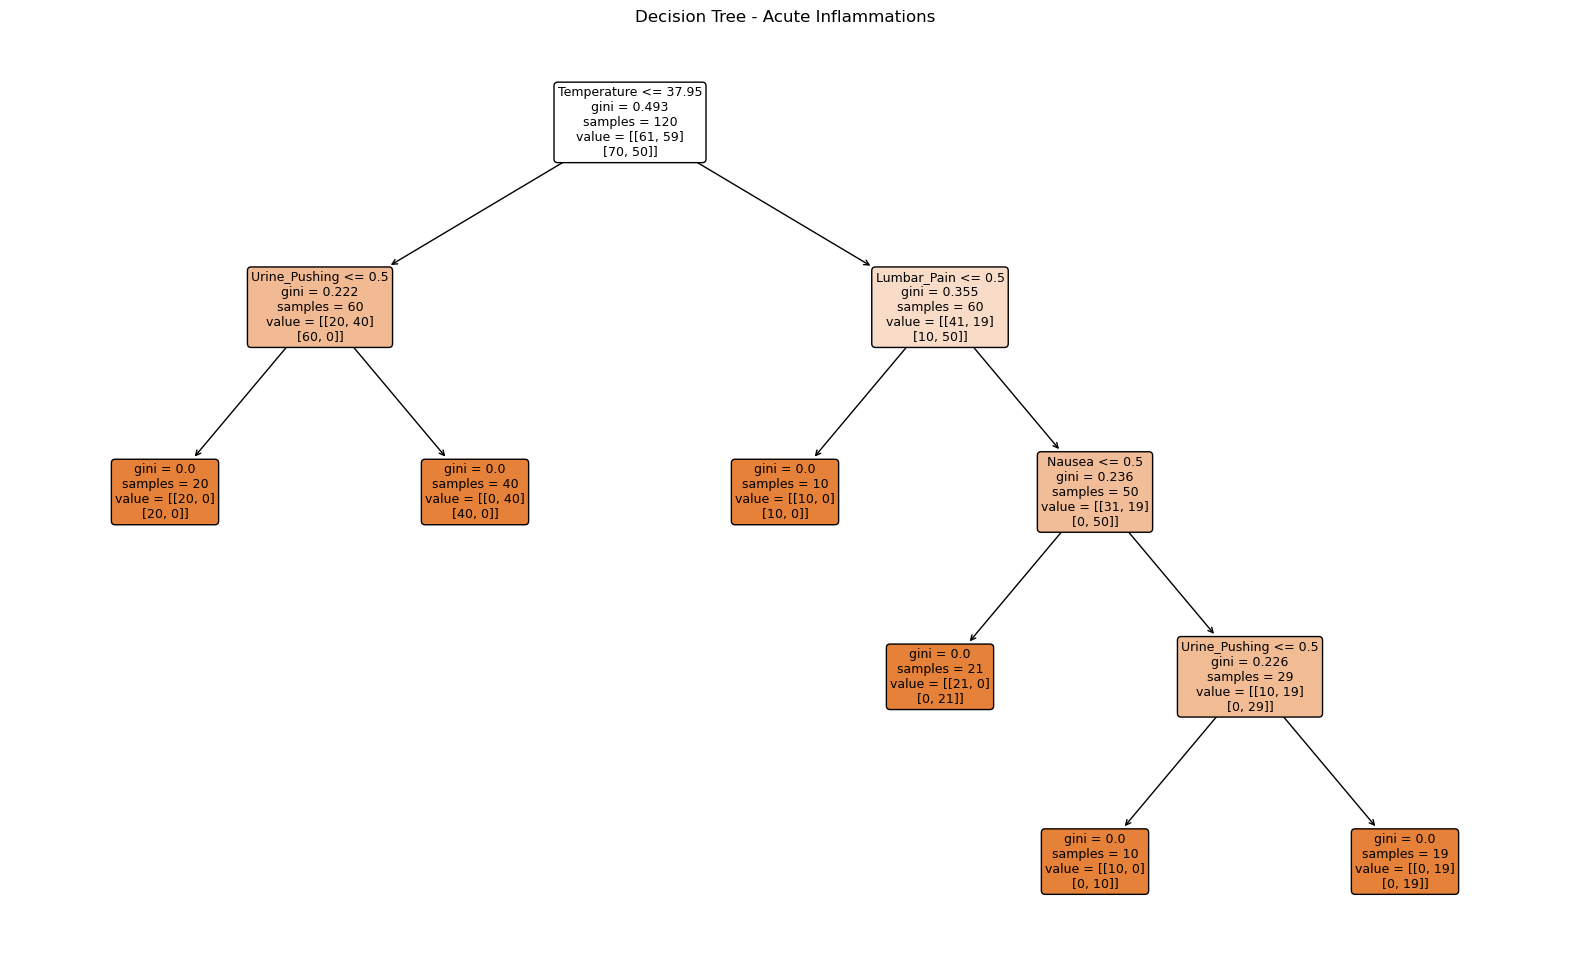

Training Accuracy: 1.0


In [2]:
# Question 1(b): Build and Plot Decision Tree

import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Separate features and target variables
X = df.iloc[:, :6].copy()
y = df.iloc[:, 6:].copy()

# Convert yes/no values into 1/0
for col in X.columns[1:]:
    X[col] = X[col].map({"yes": 1, "no": 0})

for col in y.columns:
    y[col] = y[col].map({"yes": 1, "no": 0})

# Build decision tree using the entire dataset
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X, y)

# Plot decision tree
plt.figure(figsize=(20, 12))

plot_tree(
    tree_model,
    feature_names=X.columns.tolist(),
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree - Acute Inflammations")
plt.show()

print("Training Accuracy:", tree_model.score(X, y))

In [3]:
# Question 1(c): Convert Decision Tree to IF-THEN Rules

from sklearn.tree import _tree

def get_rules(tree, feature_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined"
        for i in tree_.feature
    ]

    def recurse(node, conditions):
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]

            recurse(
                tree_.children_left[node],
                conditions + [f"{name} <= {threshold:.2f}"]
            )

            recurse(
                tree_.children_right[node],
                conditions + [f"{name} > {threshold:.2f}"]
            )
        else:
            predictions = tree_model.predict(
                [get_sample_from_conditions(conditions)]
            ) if False else None

            print("IF " + " AND ".join(conditions))
            print("THEN leaf values =", tree_.value[node])
            print("-" * 60)

    recurse(0, [])

get_rules(tree_model, X.columns.tolist())

IF Temperature <= 37.95 AND Urine_Pushing <= 0.50
THEN leaf values = [[20.  0.]
 [20.  0.]]
------------------------------------------------------------
IF Temperature <= 37.95 AND Urine_Pushing > 0.50
THEN leaf values = [[ 0. 40.]
 [40.  0.]]
------------------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain <= 0.50
THEN leaf values = [[10.  0.]
 [10.  0.]]
------------------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea <= 0.50
THEN leaf values = [[21.  0.]
 [ 0. 21.]]
------------------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing <= 0.50
THEN leaf values = [[10.  0.]
 [ 0. 10.]]
------------------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing > 0.50
THEN leaf values = [[ 0. 19.]
 [ 0. 19.]]
-----------------------------------------------------

In [4]:
# Question 1(c): Human-readable IF-THEN rules

from sklearn.tree import _tree
import numpy as np

def print_decision_rules(model, feature_names, target_names):
    tree = model.tree_

    def recurse(node, conditions):
        if tree.feature[node] != _tree.TREE_UNDEFINED:
            feature = feature_names[tree.feature[node]]
            threshold = tree.threshold[node]

            recurse(
                tree.children_left[node],
                conditions + [f"{feature} <= {threshold:.2f}"]
            )

            recurse(
                tree.children_right[node],
                conditions + [f"{feature} > {threshold:.2f}"]
            )
        else:
            print("IF " + " AND ".join(conditions))

            for i, target in enumerate(target_names):
                predicted_class = np.argmax(tree.value[node][i])
                diagnosis = model.classes_[i][predicted_class]
                result = "Yes" if diagnosis == 1 else "No"
                print(f"THEN {target} = {result}")

            print("-" * 60)

    recurse(0, [])

print_decision_rules(
    tree_model,
    X.columns.tolist(),
    y.columns.tolist()
)

IF Temperature <= 37.95 AND Urine_Pushing <= 0.50
THEN Bladder_Inflammation = No
THEN Renal_Pelvis_Nephritis = No
------------------------------------------------------------
IF Temperature <= 37.95 AND Urine_Pushing > 0.50
THEN Bladder_Inflammation = Yes
THEN Renal_Pelvis_Nephritis = No
------------------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain <= 0.50
THEN Bladder_Inflammation = No
THEN Renal_Pelvis_Nephritis = No
------------------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea <= 0.50
THEN Bladder_Inflammation = No
THEN Renal_Pelvis_Nephritis = Yes
------------------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing <= 0.50
THEN Bladder_Inflammation = No
THEN Renal_Pelvis_Nephritis = Yes
------------------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Uri

In [5]:
# Question 1(d): Cost-Complexity Pruning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

# Calculate effective alpha values for pruning
path = tree_model.cost_complexity_pruning_path(X, y)
ccp_alphas = np.unique(path.ccp_alphas)

# Train trees using different alpha values
results = []

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )
    model.fit(X, y)

    results.append({
        "Alpha": alpha,
        "Nodes": model.tree_.node_count,
        "Leaves": model.tree_.n_leaves,
        "Depth": model.tree_.max_depth,
        "Training Accuracy": model.score(X, y)
    })

results_df = pd.DataFrame(results)

display(results_df)

,Alpha,Nodes,Leaves,Depth,Training Accuracy
0,0.000000,11,6,4,1.000000
1,0.049083,7,4,2,0.841667
2,0.079472,5,3,2,0.758333
3,0.111111,3,2,1,0.591667
4,0.204236,1,1,0,0.250000


In [6]:
# Question 1(d): Compare pruning accuracy

print(
    results_df[
        ["Alpha", "Nodes", "Leaves", "Depth", "Training Accuracy"]
    ].to_string(index=False)
)

   Alpha  Nodes  Leaves  Depth  Training Accuracy
0.000000     11       6      4           1.000000
0.049083      7       4      2           0.841667
0.079472      5       3      2           0.758333
0.111111      3       2      1           0.591667
0.204236      1       1      0           0.250000


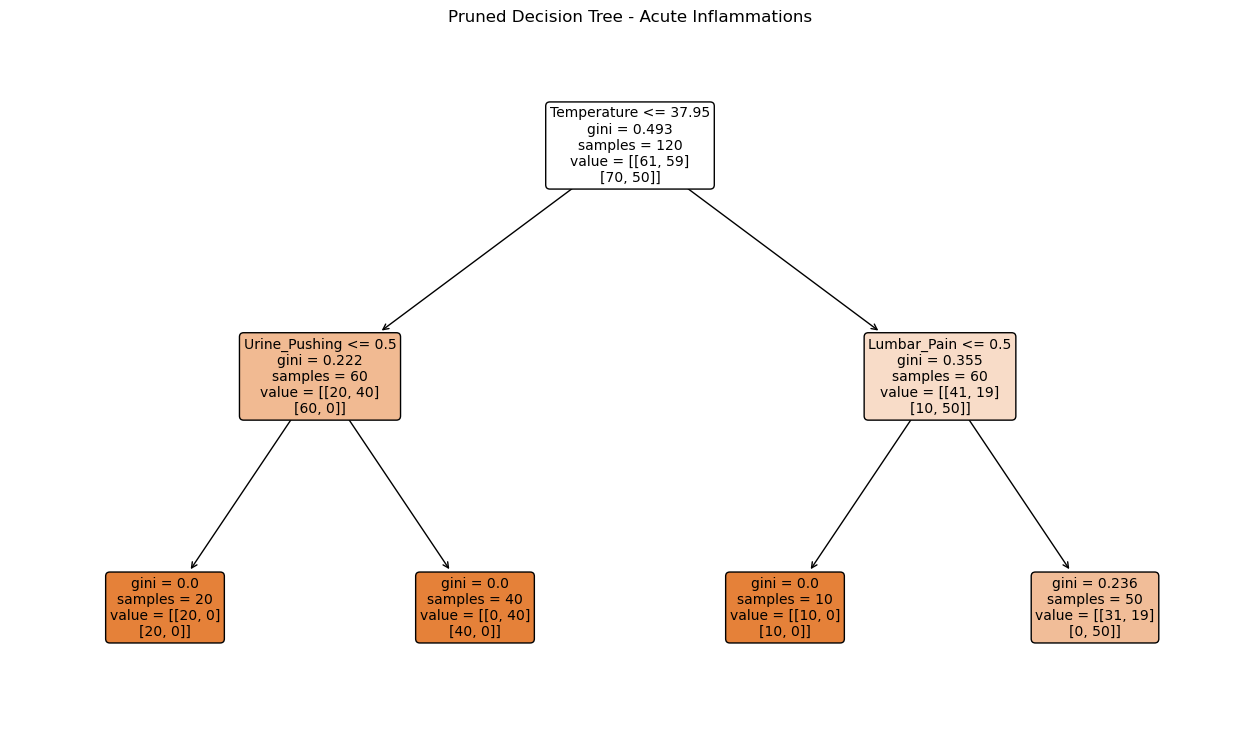

Selected Alpha: 0.04908333333333333
Number of Leaves: 4
Training Accuracy: 0.8416666666666667


In [7]:
# Question 1(d): Plot Pruned Decision Tree

from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Select pruning alpha
best_alpha = ccp_alphas[1]

# Train pruned decision tree
pruned_tree = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha
)

pruned_tree.fit(X, y)

# Plot pruned tree
plt.figure(figsize=(16, 9))

plot_tree(
    pruned_tree,
    feature_names=X.columns.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Pruned Decision Tree - Acute Inflammations")
plt.show()

print("Selected Alpha:", best_alpha)
print("Number of Leaves:", pruned_tree.get_n_leaves())
print("Training Accuracy:", pruned_tree.score(X, y))

In [8]:
# Question 1(d): IF-THEN Rules for Pruned Decision Tree

print("IF-THEN Rules for Pruned Decision Tree")
print("=" * 60)

print_decision_rules(
    pruned_tree,
    X.columns.tolist(),
    y.columns.tolist()
)

print("\nPruned Tree Summary")
print("Selected Alpha:", best_alpha)
print("Number of Leaves:", pruned_tree.get_n_leaves())
print("Training Accuracy:", pruned_tree.score(X, y))

IF-THEN Rules for Pruned Decision Tree
IF Temperature <= 37.95 AND Urine_Pushing <= 0.50
THEN Bladder_Inflammation = No
THEN Renal_Pelvis_Nephritis = No
------------------------------------------------------------
IF Temperature <= 37.95 AND Urine_Pushing > 0.50
THEN Bladder_Inflammation = Yes
THEN Renal_Pelvis_Nephritis = No
------------------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain <= 0.50
THEN Bladder_Inflammation = No
THEN Renal_Pelvis_Nephritis = No
------------------------------------------------------------
IF Temperature > 37.95 AND Lumbar_Pain > 0.50
THEN Bladder_Inflammation = No
THEN Renal_Pelvis_Nephritis = Yes
------------------------------------------------------------

Pruned Tree Summary
Selected Alpha: 0.04908333333333333
Number of Leaves: 4
Training Accuracy: 0.8416666666666667


In [9]:
# Question 2(a): Load Communities and Crime Dataset

import pandas as pd

crime_df = pd.read_csv(
    "../data/communities.data",
    header=None,
    na_values="?"
)

print("Dataset Shape:", crime_df.shape)
print("Total Rows:", len(crime_df))
print("Total Columns:", crime_df.shape[1])

display(crime_df.head())

Dataset Shape: (1994, 128)
Total Rows: 1994
Total Columns: 128


,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [10]:
# Question 2(a): Feature Names and Train-Test Split

import re

# Extract feature names from communities.names
feature_names = []

with open("../data/communities.names", "r", encoding="latin-1") as file:
    for line in file:
        match = re.match(r"^\s*@attribute\s+(\S+)", line, re.IGNORECASE)
        if match:
            feature_names.append(match.group(1))

print("Feature names found:", len(feature_names))

# Assign feature names
assert len(feature_names) == crime_df.shape[1], \
    "Feature count does not match dataset columns"

crime_df.columns = feature_names

# Remove nonpredictive columns
nonpredictive = ["state", "county", "community", "communityname", "fold"]

crime_df = crime_df.drop(columns=nonpredictive)

# Split data according to assignment instructions
train_df = crime_df.iloc[:1495].copy()
test_df = crime_df.iloc[1495:].copy()

print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

display(train_df.head())

Feature names found: 128
Training Shape: (1495, 123)
Testing Shape: (499, 123)


,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [11]:
# Question 2(b): Handle Missing Values

import numpy as np
from sklearn.impute import SimpleImputer

# Separate features and target variable
target = "ViolentCrimesPerPop"

X_train = train_df.drop(columns=[target])
y_train = train_df[target]

X_test = test_df.drop(columns=[target])
y_test = test_df[target]

# Check missing values before imputation
print("Missing values in training:", X_train.isna().sum().sum())
print("Missing values in testing:", X_test.isna().sum().sum())

# Replace missing values using training medians
imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Check results
print("\nAfter Imputation:")
print("Training Shape:", X_train_imputed.shape)
print("Testing Shape:", X_test_imputed.shape)

print("Missing values in training:", X_train_imputed.isna().sum().sum())
print("Missing values in testing:", X_test_imputed.isna().sum().sum())

Missing values in training: 27633
Missing values in testing: 9218

After Imputation:
Training Shape: (1495, 122)
Testing Shape: (499, 122)
Missing values in training: 0
Missing values in testing: 0


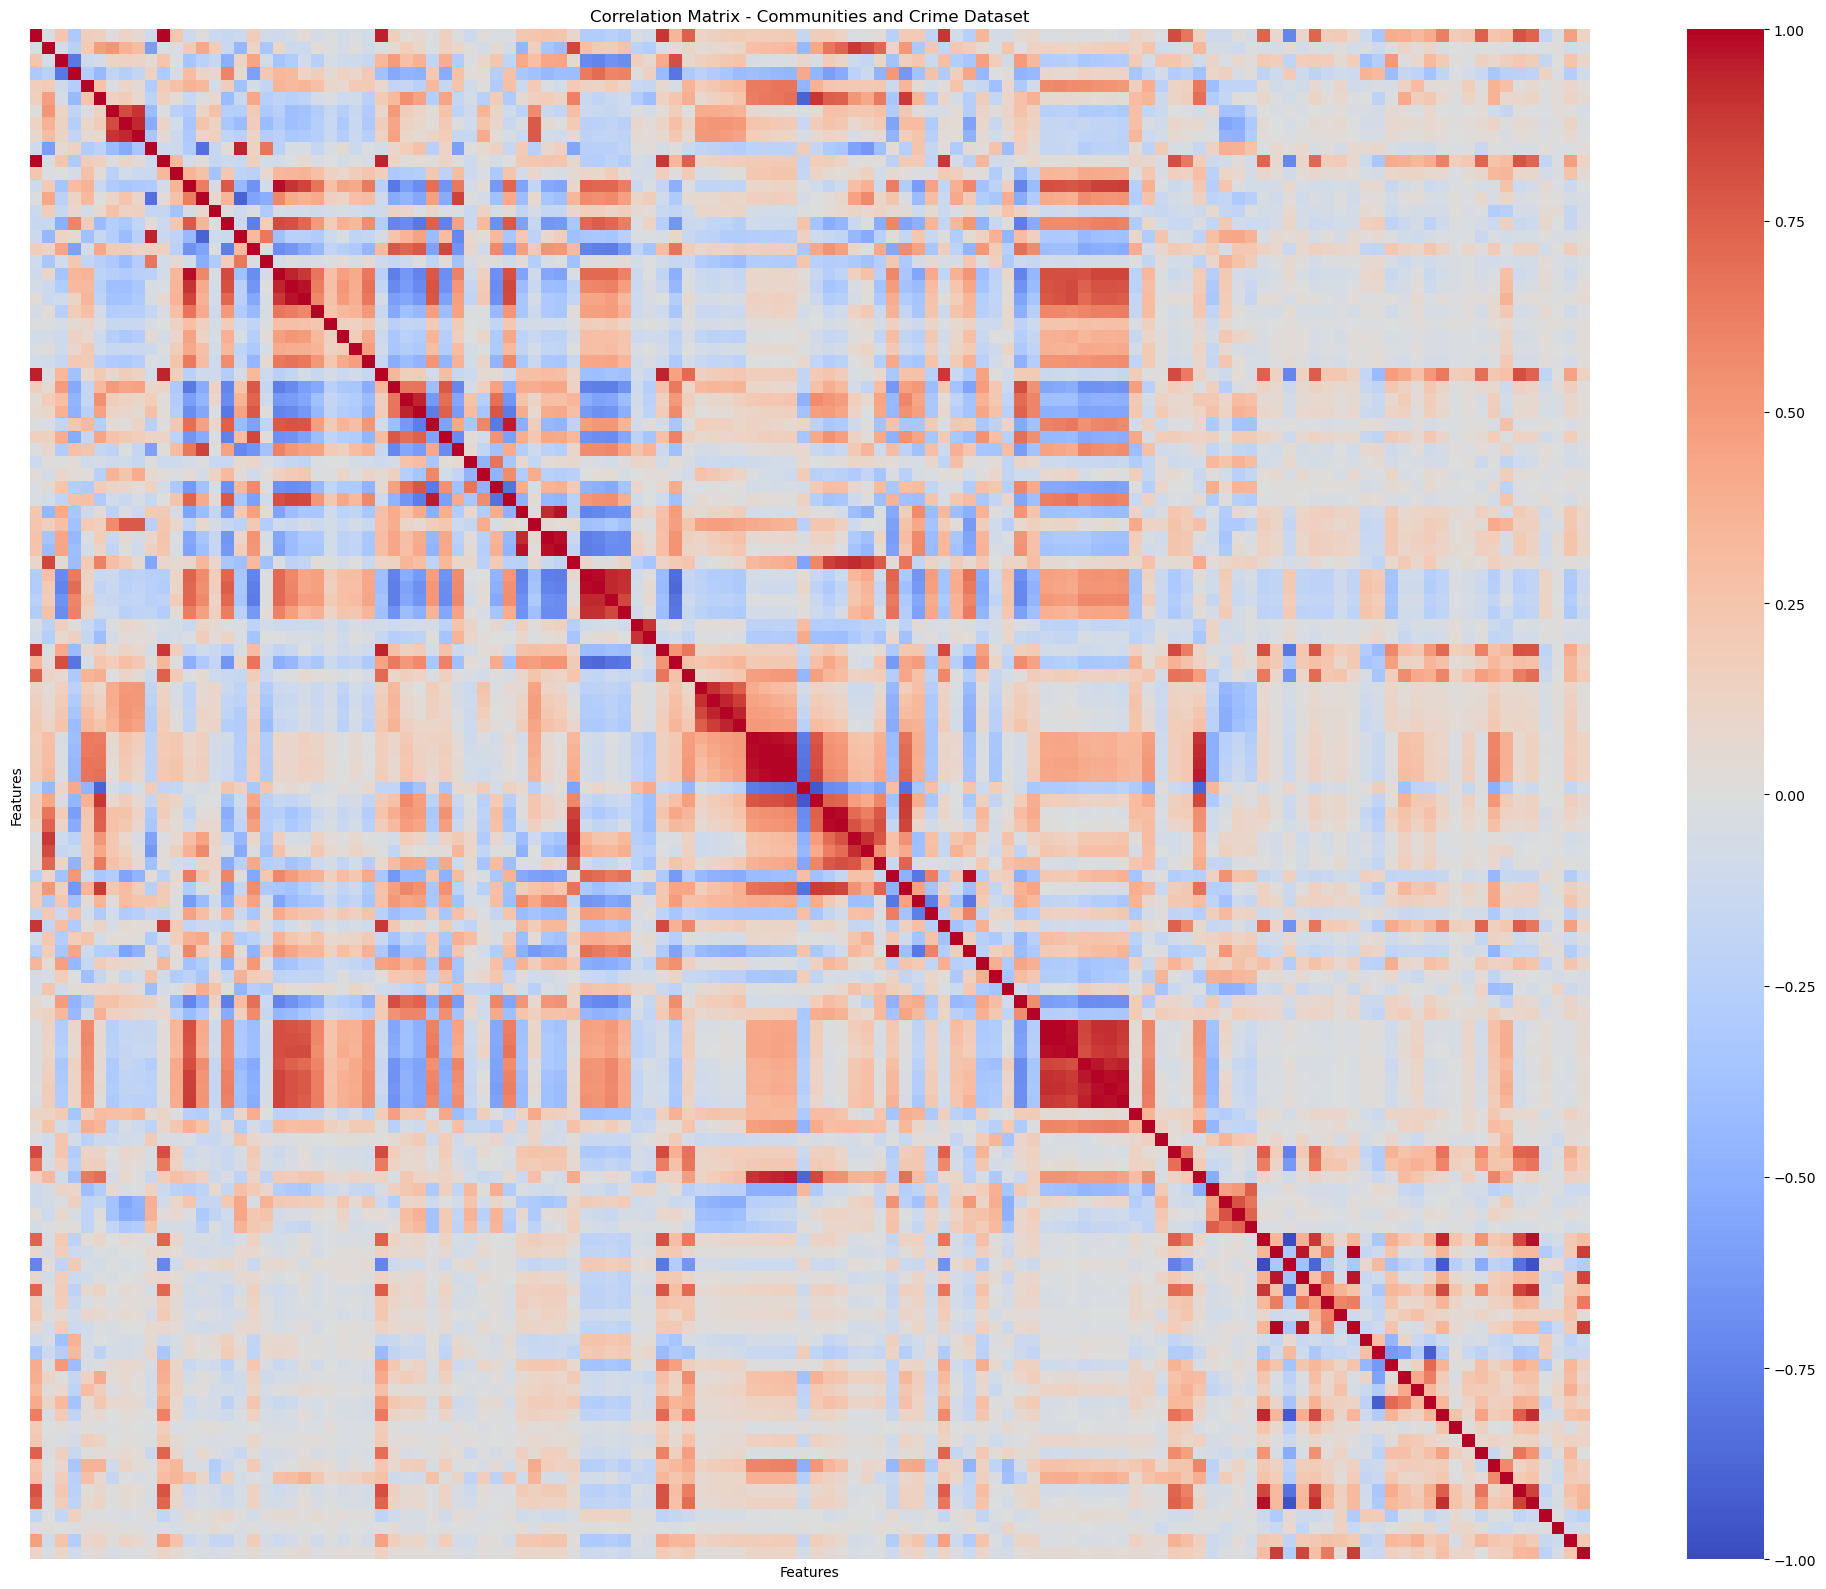

Correlation Matrix Shape: (122, 122)


In [12]:
# Question 2(c): Correlation Matrix

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix using training features
correlation_matrix = X_train_imputed.corr()

# Plot correlation heatmap
plt.figure(figsize=(20, 16))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Matrix - Communities and Crime Dataset")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

print("Correlation Matrix Shape:", correlation_matrix.shape)

In [13]:
# Question 2(d): Coefficient of Variation

import numpy as np
import pandas as pd

# Calculate mean and sample standard deviation
feature_means = X_train_imputed.mean()
feature_std = X_train_imputed.std(ddof=1)

# Calculate coefficient of variation
cv = feature_std / feature_means.replace(0, np.nan)

# Create results table
cv_df = pd.DataFrame({
    "Feature": X_train_imputed.columns,
    "Mean": feature_means.values,
    "Standard Deviation": feature_std.values,
    "CV": cv.values
})

# Sort by highest CV
cv_df = cv_df.sort_values(
    by="CV",
    ascending=False
).reset_index(drop=True)

print("Total Features:", len(cv_df))
display(cv_df)

Total Features: 122


,Feature,Mean,Standard Deviation,CV
0,PctPolicAsian,0.016254,0.089838,5.527059
1,NumStreet,0.022983,0.098665,4.292923
2,NumInShelters,0.029599,0.102736,3.470952
3,NumIlleg,0.037204,0.113806,3.058964
4,NumImmig,0.030595,0.089541,2.926635
...,...,...,...,...
117,NumKindsDrugsSeiz,0.567130,0.079977,0.141021
118,RacialMatchCommPol,0.722375,0.093657,0.129652
119,PctPolicWhite,0.762856,0.090572,0.118727
120,LemasPctPolicOnPatr,0.752495,0.084304,0.112032


In [14]:
# Question 2(e): Select Top 11 Features by CV

import numpy as np

# Number of features to select
n_features = int(np.sqrt(128))

# Select features with highest CV
top_features = cv_df["Feature"].head(n_features).tolist()

print("Number of selected features:", n_features)
print("\nSelected Features:")

for i, feature in enumerate(top_features, 1):
    print(f"{i}. {feature}")

# Create dataset with selected features
X_top = X_train_imputed[top_features]

print("\nSelected Dataset Shape:", X_top.shape)

Number of selected features: 11

Selected Features:
1. PctPolicAsian
2. NumStreet
3. NumInShelters
4. NumIlleg
5. NumImmig
6. LemasPctOfficDrugUn
7. NumUnderPov
8. LemasSwornFT
9. population
10. numbUrban
11. HousVacant

Selected Dataset Shape: (1495, 11)


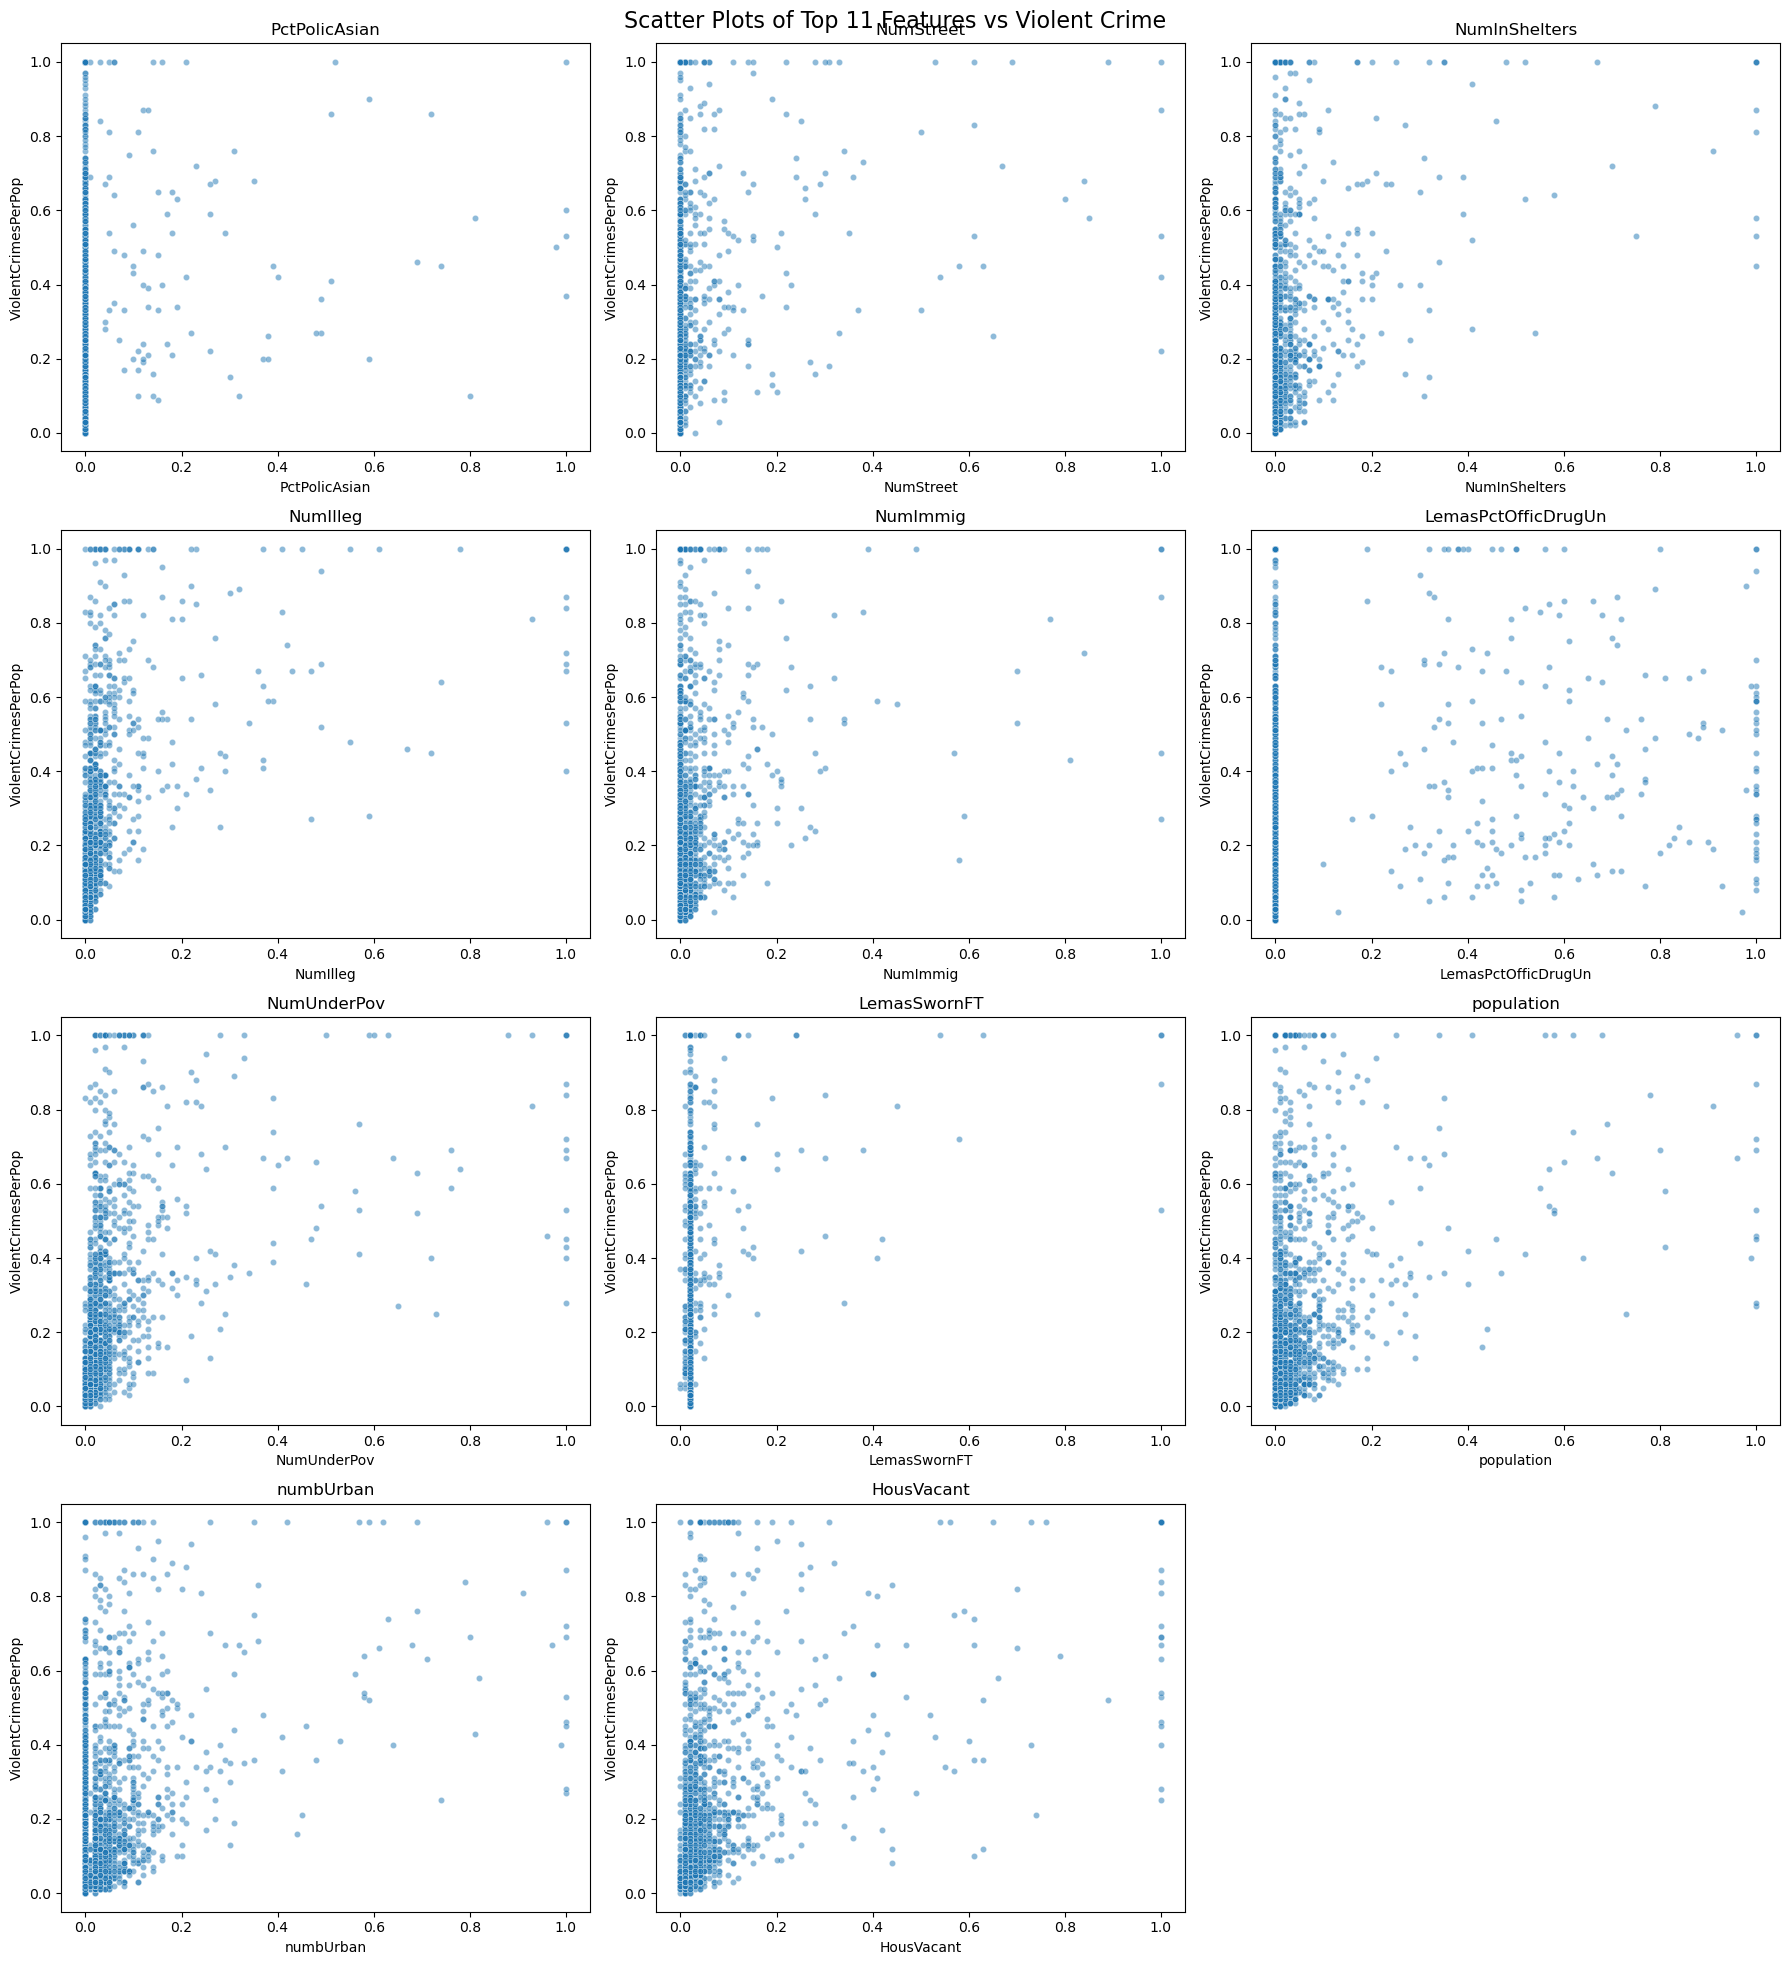

In [15]:
# Question 2(e): Scatter Plots for Top 11 CV Features

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.scatterplot(
        x=X_train_imputed[feature],
        y=y_train,
        ax=axes[i],
        alpha=0.5,
        s=20
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("ViolentCrimesPerPop")

# Hide unused subplot
for j in range(len(top_features), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Scatter Plots of Top 11 Features vs Violent Crime",
    fontsize=16
)

plt.tight_layout()
plt.show()

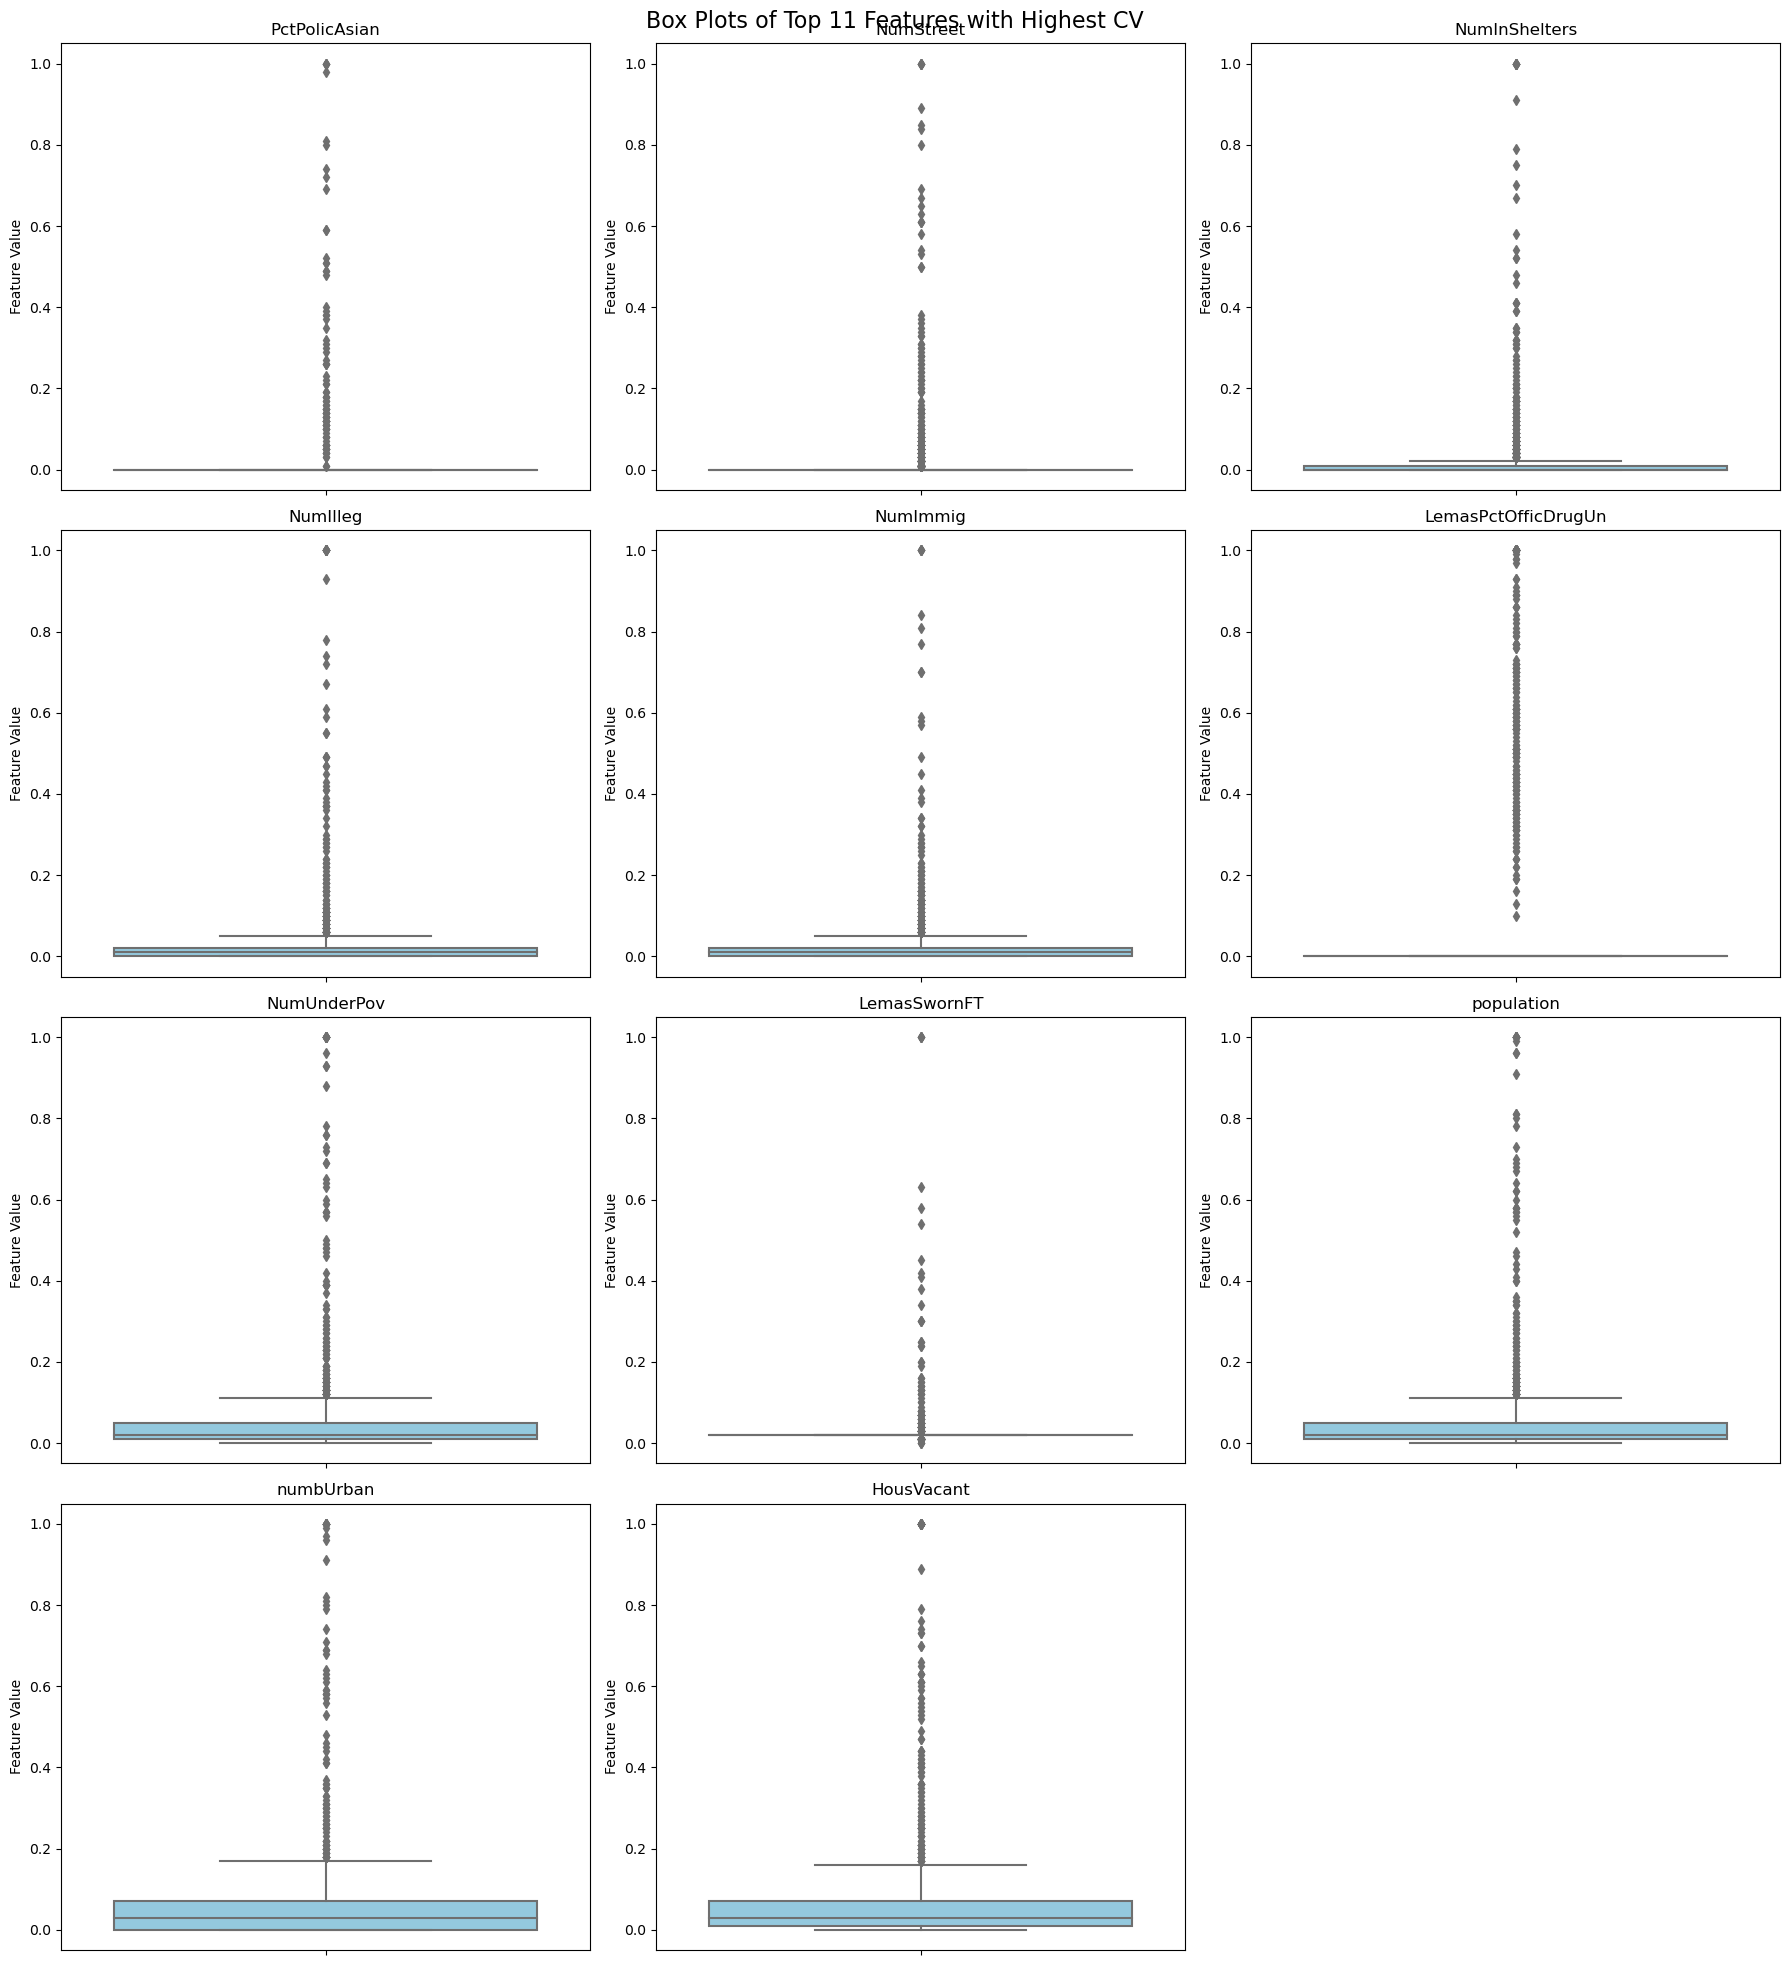

In [16]:
# Question 2(e): Box Plots for Top 11 CV Features

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.boxplot(
        y=X_train_imputed[feature],
        ax=axes[i],
        color="skyblue"
    )

    axes[i].set_title(feature)
    axes[i].set_ylabel("Feature Value")

# Hide unused subplot
for j in range(len(top_features), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Box Plots of Top 11 Features with Highest CV",
    fontsize=16
)

plt.tight_layout()
plt.show()

Question 2(e) — Interpretation

The scatter plots show that most features do not have a clear linear relationship with violent crime rates. Many observations are concentrated near zero, and several features contain outliers. The box plots also show skewed distributions.

We cannot determine the statistical significance of these features from scatter plots alone. Further statistical analysis and regression modeling are needed to evaluate their importance.

In [17]:
# Question 2(f): Least Squares Linear Regression

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

# Create and train the linear regression model
linear_model = LinearRegression()
linear_model.fit(X_train_imputed, y_train)

# Predict on the test dataset
y_pred_linear = linear_model.predict(X_test_imputed)

# Calculate test error
linear_test_mse = mean_squared_error(y_test, y_pred_linear)

print("Question 2(f): Least Squares Regression")
print("Test MSE:", linear_test_mse)
print("Test RMSE:", np.sqrt(linear_test_mse))
print("Number of Features:", X_train_imputed.shape[1])

Question 2(f): Least Squares Regression
Test MSE: 0.017966215426067335
Test RMSE: 0.13403811184162262
Number of Features: 122


In [18]:
# Question 2(g): Ridge Regression with Cross-Validation

import numpy as np
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error

# Define candidate lambda values
alphas = np.logspace(-4, 4, 100)

# Ridge regression with 5-fold cross-validation
ridge_model = RidgeCV(
    alphas=alphas,
    cv=5,
    scoring="neg_mean_squared_error"
)

# Train model
ridge_model.fit(X_train_imputed, y_train)

# Predict on test data
y_pred_ridge = ridge_model.predict(X_test_imputed)

# Calculate test error
ridge_test_mse = mean_squared_error(y_test, y_pred_ridge)

print("Question 2(g): Ridge Regression")
print("Best Lambda:", ridge_model.alpha_)
print("Test MSE:", ridge_test_mse)
print("Test RMSE:", np.sqrt(ridge_test_mse))

Question 2(g): Ridge Regression
Best Lambda: 2.310129700083163
Test MSE: 0.01751624930256487
Test RMSE: 0.13234896789384068


In [19]:
# Question 2(h): LASSO Regression Without Standardization

import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error

# Train LASSO using 5-fold cross-validation
lasso_model = LassoCV(
    cv=5,
    random_state=42,
    max_iter=100000,
    n_alphas=100
)

lasso_model.fit(X_train_imputed, y_train)

# Predict on test data
y_pred_lasso = lasso_model.predict(X_test_imputed)

# Calculate test error
lasso_test_mse = mean_squared_error(y_test, y_pred_lasso)

# Identify selected features
selected_features = X_train_imputed.columns[
    np.abs(lasso_model.coef_) > 1e-8
].tolist()

print("Question 2(h): LASSO Without Standardization")
print("Best Lambda:", lasso_model.alpha_)
print("Test MSE:", lasso_test_mse)
print("Test RMSE:", np.sqrt(lasso_test_mse))
print("Number of Selected Features:", len(selected_features))

print("\nSelected Features:")
for i, feature in enumerate(selected_features, 1):
    print(f"{i}. {feature}")

Question 2(h): LASSO Without Standardization
Best Lambda: 0.00012454087437758517
Test MSE: 0.017617760569778627
Test RMSE: 0.13273191240157217
Number of Selected Features: 74

Selected Features:
1. racepctblack
2. racePctAsian
3. agePct12t21
4. agePct12t29
5. pctUrban
6. pctWWage
7. pctWFarmSelf
8. pctWInvInc
9. pctWSocSec
10. pctWPubAsst
11. pctWRetire
12. whitePerCap
13. blackPerCap
14. indianPerCap
15. AsianPerCap
16. OtherPerCap
17. HispPerCap
18. PctPopUnderPov
19. PctLess9thGrade
20. PctEmploy
21. PctEmplManu
22. PctOccupManu
23. MalePctDivorce
24. MalePctNevMarr
25. FemalePctDiv
26. PctKids2Par
27. PctYoungKids2Par
28. PctTeen2Par
29. PctWorkMom
30. NumIlleg
31. PctIlleg
32. NumImmig
33. PctImmigRecent
34. PctImmigRec10
35. PctRecImmig10
36. PctNotSpeakEnglWell
37. PctLargHouseOccup
38. PersPerOccupHous
39. PctPersOwnOccup
40. PctPersDenseHous
41. PctHousLess3BR
42. MedNumBR
43. HousVacant
44. PctHousOccup
45. PctVacantBoarded
46. PctVacMore6Mos
47. MedYrHousBuilt
48. PctHousNoP

In [20]:
# Question 2(h): LASSO With Standardization

import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error

# Standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Train standardized LASSO model
lasso_scaled_model = LassoCV(
    cv=5,
    random_state=42,
    max_iter=100000,
    n_alphas=100
)

lasso_scaled_model.fit(X_train_scaled, y_train)

# Predict on test data
y_pred_lasso_scaled = lasso_scaled_model.predict(X_test_scaled)

# Calculate test error
lasso_scaled_test_mse = mean_squared_error(
    y_test, y_pred_lasso_scaled
)

# Identify selected features
selected_scaled_features = X_train_imputed.columns[
    np.abs(lasso_scaled_model.coef_) > 1e-8
].tolist()

print("Question 2(h): LASSO With Standardization")
print("Best Lambda:", lasso_scaled_model.alpha_)
print("Test MSE:", lasso_scaled_test_mse)
print("Test RMSE:", np.sqrt(lasso_scaled_test_mse))
print("Number of Selected Features:", len(selected_scaled_features))

print("\nComparison:")
print("LASSO Without Standardization MSE:", lasso_test_mse)
print("LASSO With Standardization MSE:", lasso_scaled_test_mse)

print("\nSelected Features:")
for i, feature in enumerate(selected_scaled_features, 1):
    print(f"{i}. {feature}")

Question 2(h): LASSO With Standardization
Best Lambda: 0.0007630833878262516
Test MSE: 0.017682000986749827
Test RMSE: 0.13297368531686948
Number of Selected Features: 72

Comparison:
LASSO Without Standardization MSE: 0.017617760569778627
LASSO With Standardization MSE: 0.017682000986749827

Selected Features:
1. racepctblack
2. racePctAsian
3. agePct12t21
4. agePct12t29
5. pctUrban
6. pctWWage
7. pctWFarmSelf
8. pctWInvInc
9. pctWSocSec
10. pctWPubAsst
11. pctWRetire
12. whitePerCap
13. blackPerCap
14. indianPerCap
15. AsianPerCap
16. OtherPerCap
17. HispPerCap
18. PctPopUnderPov
19. PctLess9thGrade
20. PctEmploy
21. PctEmplManu
22. MalePctDivorce
23. MalePctNevMarr
24. FemalePctDiv
25. PctKids2Par
26. PctYoungKids2Par
27. PctTeen2Par
28. PctWorkMom
29. NumIlleg
30. PctIlleg
31. NumImmig
32. PctImmigRec5
33. PctImmigRec10
34. PctRecImmig10
35. PctNotSpeakEnglWell
36. PctLargHouseOccup
37. PersPerOccupHous
38. PctPersOwnOccup
39. PctPersDenseHous
40. PctHousLess3BR
41. HousVacant
42. 

In [21]:
# Question 2(i): Principal Component Regression (PCR)

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import mean_squared_error

# Create PCR pipeline
pcr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("regression", LinearRegression())
])

# Candidate numbers of principal components
components = list(range(1, 123))

# 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid={"pca__n_components": components},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

# Fit PCR model
grid_search.fit(X_train_imputed, y_train)

# Best model
best_pcr = grid_search.best_estimator_
best_M = grid_search.best_params_["pca__n_components"]

# Test predictions
y_pred_pcr = best_pcr.predict(X_test_imputed)

# Calculate test error
pcr_test_mse = mean_squared_error(y_test, y_pred_pcr)

print("Question 2(i): Principal Component Regression")
print("Best Number of Components (M):", best_M)
print("Test MSE:", pcr_test_mse)
print("Test RMSE:", np.sqrt(pcr_test_mse))

Question 2(i): Principal Component Regression
Best Number of Components (M): 60
Test MSE: 0.018364084046058833
Test RMSE: 0.1355141470329162


In [22]:
# Question 2(j): Check XGBoost Installation

try:
    import xgboost as xgb
    print("XGBoost is installed successfully!")
    print("XGBoost Version:", xgb.__version__)
except ImportError:
    print("XGBoost is not installed.")

XGBoost is installed successfully!
XGBoost Version: 3.2.0


In [23]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [24]:
# Question 2(j): Verify XGBoost

import xgboost as xgb

print("XGBoost Version:", xgb.__version__)
print("XGBoost is ready!")

XGBoost Version: 3.2.0
XGBoost is ready!


In [25]:
# Question 2(j): XGBoost with L1 Regularization

import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error

# Reload data after kernel restart
crime_data = pd.read_csv(
    "../data/communities.data",
    header=None,
    na_values="?"
)

# Remove nonpredictive columns
# Columns 0-4: state, county, community, communityname, fold
X_all = crime_data.iloc[:, 5:-1]
y_all = crime_data.iloc[:, -1]

# Split according to assignment
X_train_xgb = X_all.iloc[:1495]
X_test_xgb = X_all.iloc[1495:]

y_train_xgb = y_all.iloc[:1495]
y_test_xgb = y_all.iloc[1495:]

# Impute missing values using training data
imputer_xgb = SimpleImputer(strategy="median")

X_train_xgb = imputer_xgb.fit_transform(X_train_xgb)
X_test_xgb = imputer_xgb.transform(X_test_xgb)

# Create XGBoost regression model
xgb_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    random_state=42,
    n_jobs=2
)

# Candidate L1 regularization values
param_grid = {
    "reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]
}

# Cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=2
)

# Train model
grid_xgb.fit(X_train_xgb, y_train_xgb)

# Predict on test data
y_pred_xgb = grid_xgb.best_estimator_.predict(X_test_xgb)

# Calculate test error
xgb_test_mse = mean_squared_error(y_test_xgb, y_pred_xgb)

print("Question 2(j): XGBoost Regression")
print("Best Alpha:", grid_xgb.best_params_["reg_alpha"])
print("Test MSE:", xgb_test_mse)
print("Test RMSE:", np.sqrt(xgb_test_mse))
print("Best CV MSE:", -grid_xgb.best_score_)

Question 2(j): XGBoost Regression
Best Alpha: 0.1
Test MSE: 0.016308703349882023
Test RMSE: 0.12770553374808008
Best CV MSE: 0.02003174207350117


,Model,Test MSE
5,XGBoost,0.016309
1,Ridge Regression,0.017516
2,LASSO (Unstandardized),0.017618
3,LASSO (Standardized),0.017682
0,Linear Regression,0.017966
4,PCR,0.018306


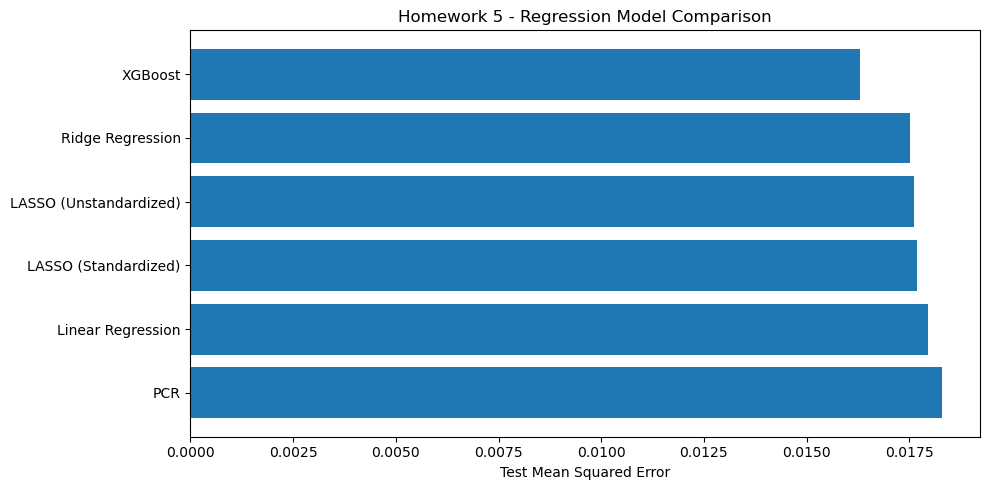

In [26]:
# Final Model Comparison - Homework 5

import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "LASSO (Unstandardized)",
        "LASSO (Standardized)",
        "PCR",
        "XGBoost"
    ],
    "Test MSE": [
        0.017966,
        0.017516,
        0.017618,
        0.017682,
        0.018306,
        0.016309
    ]
})

comparison = comparison.sort_values("Test MSE")

display(comparison)

plt.figure(figsize=(10, 5))
plt.barh(comparison["Model"], comparison["Test MSE"])
plt.xlabel("Test Mean Squared Error")
plt.title("Homework 5 - Regression Model Comparison")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Final Conclusion — Homework 5

In this assignment, I applied decision tree classification and several regression techniques to two datasets.

For Question 1, I built a decision tree using the Acute Inflammations dataset and converted it into IF-THEN rules. Cost-complexity pruning reduced the tree from 6 leaves to 4 leaves, with a training accuracy of 84.17%.

For Question 2, I analyzed the Communities and Crime dataset using Linear Regression, Ridge Regression, LASSO, Principal Component Regression, and XGBoost.

XGBoost achieved the lowest test MSE of 0.016309, with an optimal L1 regularization parameter of 0.1 among the values tested. Therefore, XGBoost performed best on the given test dataset.